In [1]:
# 1. Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

In [2]:
# 2. Load dataset
df= pd.read_csv('C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\results\\outputs\\final_result.csv')

In [3]:
print("Shape of dataset:", df.shape)
print("\nPreview of the dataset:")
print(df.head())

Shape of dataset: (36082, 12)

Preview of the dataset:
   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0   -1.397814      -1.828331       -1.050160  -1.521430       0.088373   
1   -1.397814      -1.807177       -1.050160  -1.207890      -1.277767   
2   -1.397814      -1.813881       -1.050160  -1.396014       1.317900   
3   -0.622076      -1.765060       -0.792289  -1.364660       0.037143   
4   -0.622076      -1.778245       -1.050160  -1.416916      -1.226537   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0            -0.694433                   -1.131709     -2.686426   
1             0.842289                   -1.131709     -2.099221   
2             0.004077                   -0.754295      0.165712   
3            -0.135625                   -1.131709      0.983605   
4            -0.275327                   -0.754295     -0.673152   

   previous_loan_defaults_on_file  person_home_ownership_RENT  \
0                         

In [4]:
# 3. Prepare data
# 'Loan_Status' is our target column
X = df.drop('Loan_Status', axis=1) # Features (11 features)
y = df['Loan_Status']              # Target column

In [5]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4, stratify=y
)

In [6]:
print("Data Split Completed:")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Data Split Completed:
Training samples: 28865, Testing samples: 7217


In [7]:
# Handle class imbalance with SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print("Class distribution after SMOTE:", pd.Series(y_train_res).value_counts())

Class distribution after SMOTE: Loan_Status
0    23033
1    23033
Name: count, dtype: int64


In [8]:
# 5. Hyperparameter Tuning using Nested Loops
criteria = ["gini", "entropy"]
max_depths = [3, 5, 7]
min_samples_splits = [2, 5]

param_combinations = []
for crit in criteria:
    for depth in max_depths:
        for split in min_samples_splits:
            param_combinations.append({
                "criterion": crit,
                "max_depth": depth,
                "min_samples_split": split
            })

In [11]:
# 6. Cross-validation for each parameter combination
from sklearn.model_selection import cross_validate, StratifiedKFold

cv_results = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for params in param_combinations:
    model = DecisionTreeClassifier(
        criterion=params["criterion"],
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        random_state=42
    )

    scores = cross_validate(
        model, X_train_res, y_train_res, cv=cv,
        scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
    )

    cv_results.append({
        "criterion": params["criterion"],
        "max_depth": params["max_depth"],
        "min_samples_split": params["min_samples_split"],
        "accuracy": scores['test_accuracy'].mean(),
        "precision": scores['test_precision_weighted'].mean(),
        "recall": scores['test_recall_weighted'].mean(),
        "f1_score": scores['test_f1_weighted'].mean()
    })

In [12]:
# 7. Display Model Comparison
results_df = pd.DataFrame(cv_results)
results_df.sort_values("accuracy", ascending=False, inplace=True)
print("Model Comparison (Cross-Validation Results):")
print(results_df)

Model Comparison (Cross-Validation Results):
   criterion  max_depth  min_samples_split  accuracy  precision    recall  \
4       gini          7                  2  0.882278   0.882905  0.882278   
5       gini          7                  5  0.882256   0.882882  0.882256   
10   entropy          7                  2  0.878609   0.879865  0.878609   
11   entropy          7                  5  0.878609   0.879865  0.878609   
8    entropy          5                  2  0.873703   0.876691  0.873703   
9    entropy          5                  5  0.873703   0.876691  0.873703   
2       gini          5                  2  0.866170   0.869673  0.866170   
3       gini          5                  5  0.866170   0.869673  0.866170   
0       gini          3                  2  0.855034   0.857683  0.855034   
1       gini          3                  5  0.855034   0.857683  0.855034   
6    entropy          3                  2  0.827183   0.871576  0.827183   
7    entropy          3        

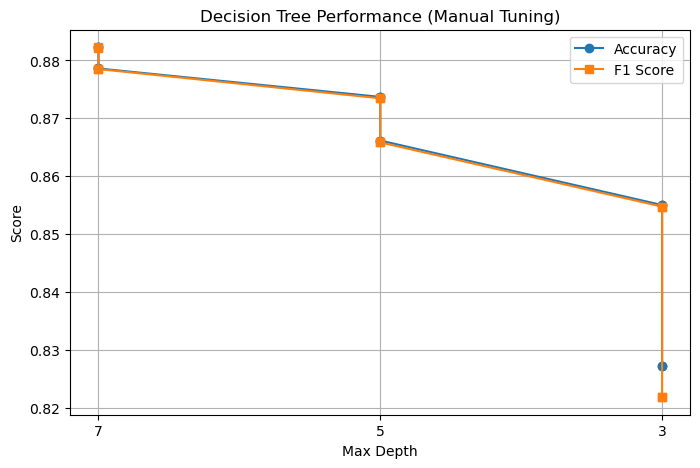

In [13]:
# Plot accuracy and F1-score for comparison
plt.figure(figsize=(8,5))
plt.plot(results_df["max_depth"].astype(str), results_df["accuracy"], marker='o', label="Accuracy")
plt.plot(results_df["max_depth"].astype(str), results_df["f1_score"], marker='s', label="F1 Score")
plt.title("Decision Tree Performance (Manual Tuning)")
plt.xlabel("Max Depth")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# 8. Select Best Model (based on accuracy)
best_model_idx = results_df["accuracy"].idxmax()
best_params = param_combinations[best_model_idx]
print("Best Model Parameters:", best_params)

Best Model Parameters: {'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 2}


In [15]:
# 9. Train best model on full resampled training data
best_model = DecisionTreeClassifier(**best_params, random_state=42)
best_model.fit(X_train_res, y_train_res)

DecisionTreeClassifier(max_depth=7, random_state=42)

In [16]:
# 10. Evaluate on test set
y_pred = best_model.predict(X_test) #predict() is how you use a trained model to make predictions on new/unseen data.
print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred))


Classification Report (Test set):
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      5759
           1       0.61      0.86      0.72      1458

    accuracy                           0.86      7217
   macro avg       0.79      0.86      0.81      7217
weighted avg       0.89      0.86      0.87      7217



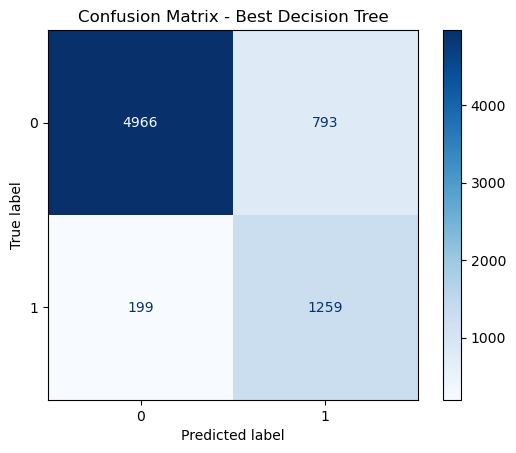

In [17]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion Matrix - Best Decision Tree")
plt.show()

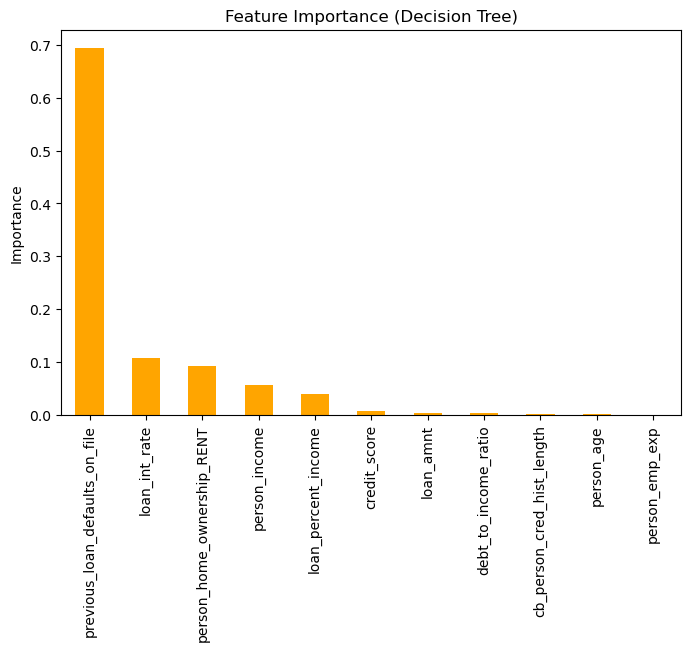

In [18]:
# 11. Feature Importance
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8,5))
importances.plot(kind="bar", color="orange")
plt.title("Feature Importance (Decision Tree)")
plt.ylabel("Importance")
plt.show()

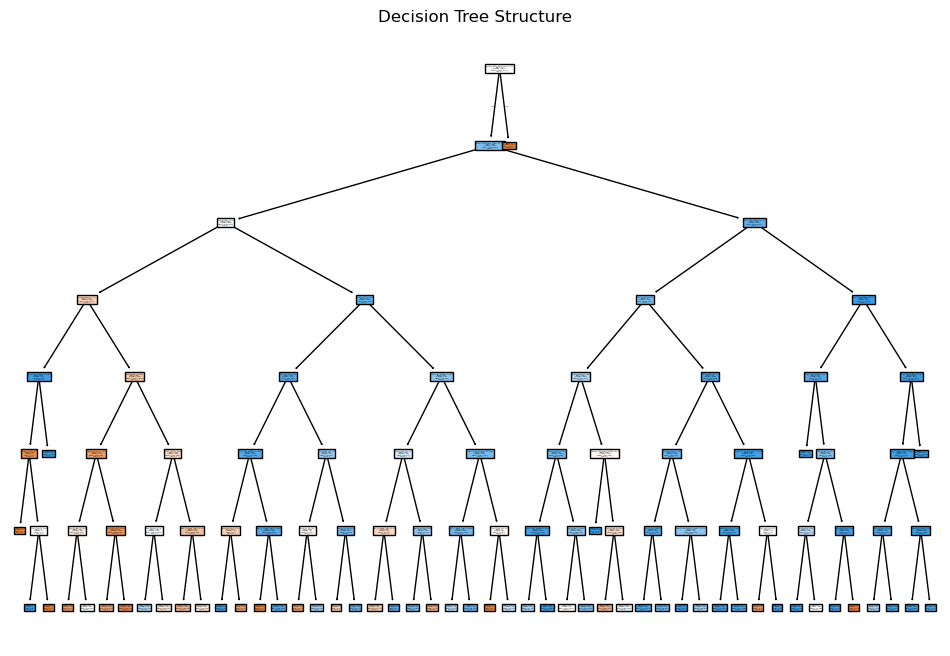

In [19]:
# 12. Visualize Decision Tree
from sklearn import tree

class_names = y.unique().astype(str)
plt.figure(figsize=(12,8))
tree.plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=class_names,
    filled=True
)
plt.title("Decision Tree Structure")
plt.show()

In [20]:
# 13. PCA and 2D Decision Boundary Visualization
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_res)
X_test_pca = pca.transform(X_test)

In [21]:
dt_pca = DecisionTreeClassifier(**best_params, random_state=42)
dt_pca.fit(X_train_pca, y_train_res)

DecisionTreeClassifier(max_depth=7, random_state=42)

In [22]:
# Create mesh grid for decision boundary
import numpy as np

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

In [23]:
Z = dt_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

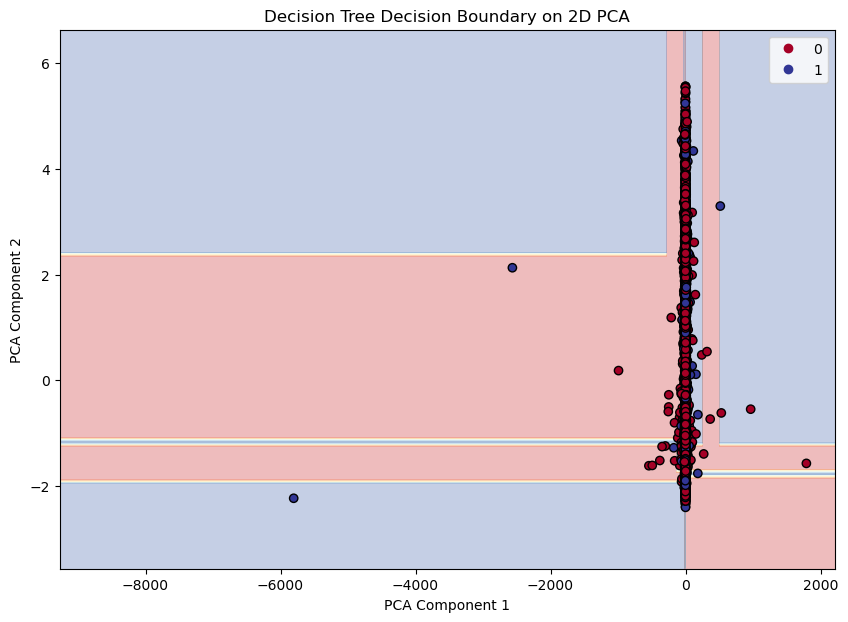

In [24]:
# Plot decision boundary with test points
plt.figure(figsize=(10,7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap=plt.cm.RdYlBu, edgecolor='k')
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Decision Tree Decision Boundary on 2D PCA")
plt.legend(handles=scatter.legend_elements()[0], labels=list(np.unique(y)))
plt.show()